# Week 10: Data Clustering Solutions
## K-Means and Hierarchical Clustering

This notebook solves the questions from the Week 10 Data Clustering lab.


## Question 1: Basketball Players Data
### Data Loading

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns

# Basketball data (18 points as listed)
data_points = [
    [18.0, 3.0, 15],
    [19.0, 4.0, 14],
    [14.0, 5.0, 10],
    [14.0, 4.0, 8],
    [11.0, 7.0, 14],
    [20.0, 8.0, 13],
    [28.0, 7.0, 9],
    [30.0, 6.0, 5],
    [31.0, 9.0, 4],
    [35.0, 12.0, 11],
    [33.0, 14.0, 6],
    [25.0, 9.0, 5],
    [25.0, 4.0, 3],
    [27.0, 3.0, 8],
    [29.0, 4.0, 12],
    [30.0, 12.0, 7],
    [19.0, 15.0, 6],
    [23.0, 11.0, 5]
]

df = pd.DataFrame(data_points, columns=['points', 'assists', 'rebounds'])
print(df)
X = df.values
print(f"Data shape: {X.shape}")


    points  assists  rebounds
0     18.0      3.0        15
1     19.0      4.0        14
2     14.0      5.0        10
3     14.0      4.0         8
4     11.0      7.0        14
5     20.0      8.0        13
6     28.0      7.0         9
7     30.0      6.0         5
8     31.0      9.0         4
9     35.0     12.0        11
10    33.0     14.0         6
11    25.0      9.0         5
12    25.0      4.0         3
13    27.0      3.0         8
14    29.0      4.0        12
15    30.0     12.0         7
16    19.0     15.0         6
17    23.0     11.0         5
Data shape: (18, 3)


### Manual K-Means Clustering with K=2 (One Iteration, Euclidean Distance)

**Initial Centroids Selection:**  
For demonstration, we select two points as initial centroids:  
- C1: Point 0 (18, 3, 15)  
- C2: Point 9 (35, 12, 11)

**Step 1: Compute Euclidean distances and assign clusters.**

In [11]:
# Manual one iteration
centroids = np.array([[18.0, 3.0, 15.0], [35.0, 12.0, 11.0]])
print("Initial Centroids:")
print(centroids)

# Euclidean distances
dists = np.sqrt(((X[:, np.newaxis, :] - centroids)**2).sum(axis=2))
print("\nDistances to C1 and C2:")
print(dists.round(2))

assignments = np.argmin(dists, axis=1)
print("\nCluster Assignments (0 or 1):")
print(assignments)

# Update centroids
new_centroids = np.array([X[assignments == i].mean(axis=0) for i in range(2)])
print("\nUpdated Centroids after one iteration:")
print(new_centroids.round(2))


Initial Centroids:
[[18.  3. 15.]
 [35. 12. 11.]]

Distances to C1 and C2:
[[ 0.   19.65]
 [ 1.73 18.14]
 [ 6.71 22.16]
 [ 8.12 22.67]
 [ 8.12 24.7 ]
 [ 5.74 15.65]
 [12.33  8.83]
 [15.91  9.85]
 [18.06  8.6 ]
 [19.65  0.  ]
 [20.66  5.74]
 [13.6  12.04]
 [13.93 15.1 ]
 [11.4  12.41]
 [11.45 10.05]
 [17.    6.4 ]
 [15.03 17.03]
 [13.75 13.45]]

Cluster Assignments (0 or 1):
[0 0 0 0 0 0 1 1 1 1 1 1 0 0 1 1 0 1]

Updated Centroids after one iteration:
[[18.56  5.89 10.11]
 [29.33  9.33  7.11]]


This completes one full iteration of assignment and centroid update. Repeat until convergence for full clustering.

### Python Implementation of K-Means (without scikit-learn)
Supports Euclidean, Manhattan, and Minkowski distances.

In [12]:
class KMeansCustom:
    def __init__(self, n_clusters=3, max_iter=100, metric='euclidean', p=2, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.metric = metric
        self.p = p
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = None
        self.sse_history = []
    
    def _distance(self, X, centroids):
        if self.metric == 'euclidean':
            return np.sqrt(((X[:, np.newaxis, :] - centroids)**2).sum(axis=2))
        elif self.metric == 'manhattan':
            return np.abs(X[:, np.newaxis, :] - centroids).sum(axis=2)
        elif self.metric == 'minkowski':
            return (np.abs(X[:, np.newaxis, :] - centroids)**self.p).sum(axis=2)**(1/self.p)
        else:
            raise ValueError("Unsupported metric")
    
    def fit(self, X):
        np.random.seed(self.random_state)
        # Random init
        indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.centroids = X[indices].copy()
        
        for iter_num in range(self.max_iter):
            dists = self._distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)
            
            # SSE for this iteration (using Euclidean for consistency in inertia)
            sse = 0
            for k in range(self.n_clusters):
                if np.any(labels == k):
                    sse += ((X[labels == k] - self.centroids[k])**2).sum()
            self.sse_history.append(sse)
            
            new_centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else self.centroids[k] 
                                      for k in range(self.n_clusters)])
            
            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids
        
        self.labels_ = labels
        self.inertia_ = self.sse_history[-1]
        return self
    
    def predict(self, X):
        dists = self._distance(X, self.centroids)
        return np.argmin(dists, axis=1)

print("KMeansCustom class defined.")


KMeansCustom class defined.


### Tasks for Euclidean Distance
a. Scatter plot of data points (using first two features for visualization)  
b. Cluster plots for K=1,2,3,4  
c. SSE vs K plot  
d. Elbow method

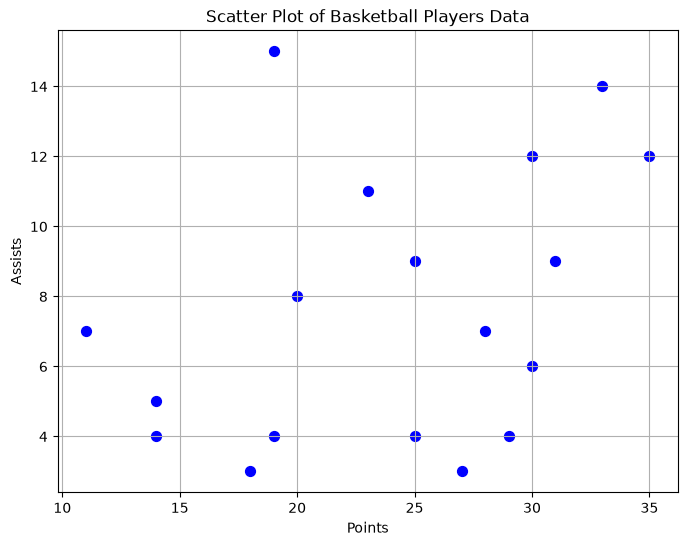

=== Euclidean Distance ===


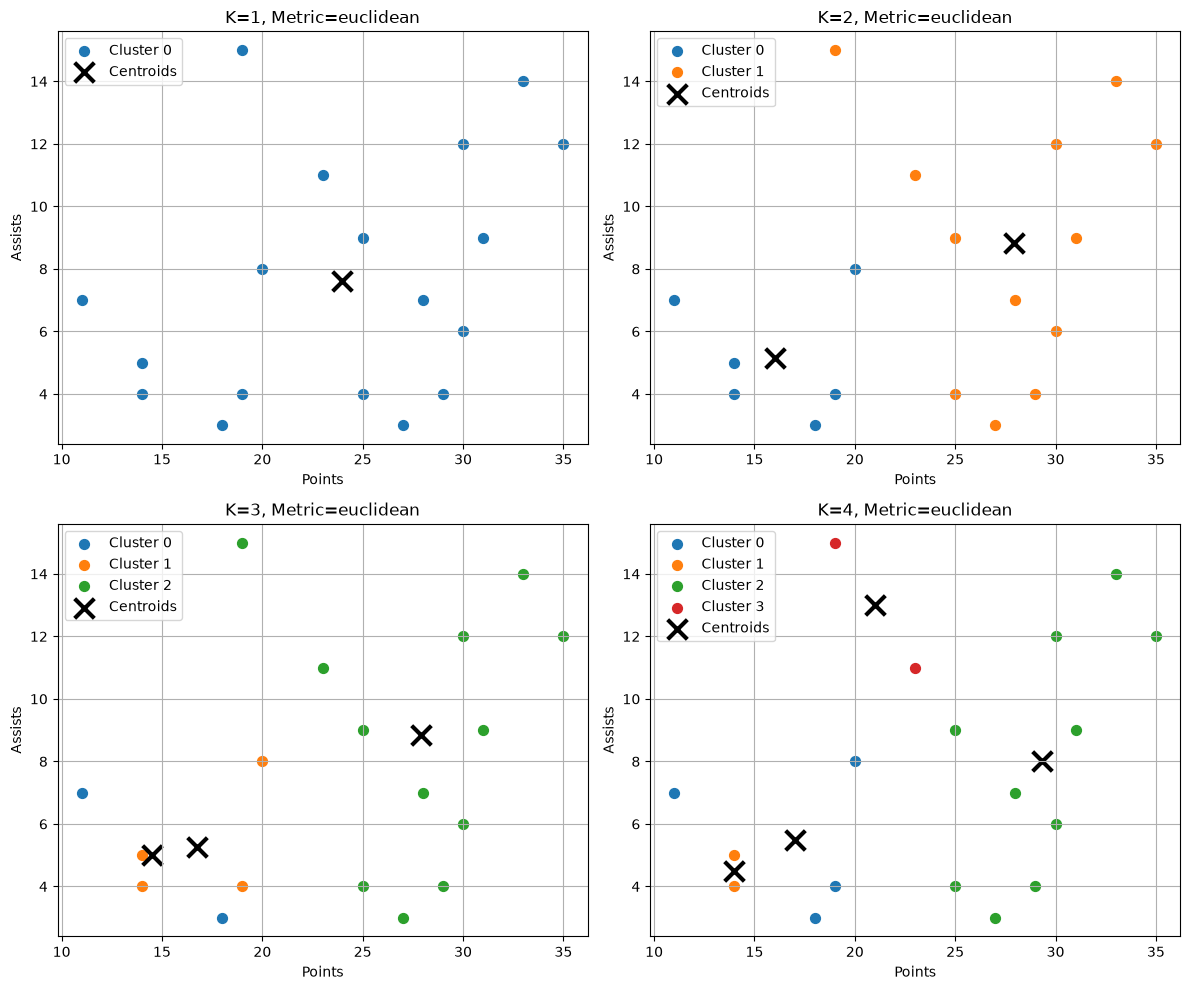

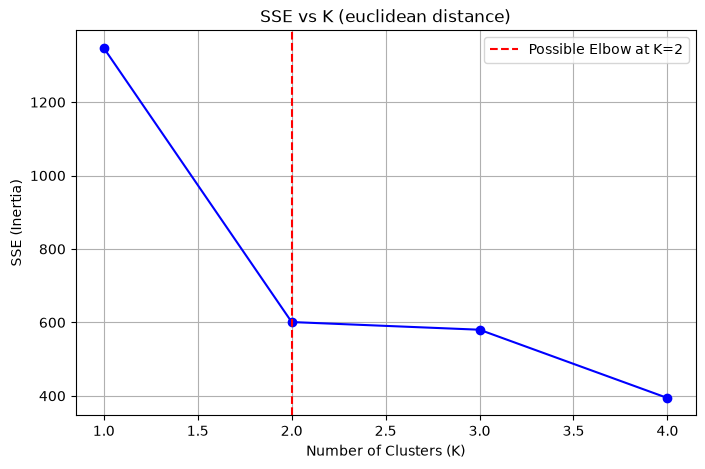

SSE values for K=1 to 4: [np.float64(1347.5000000000002), np.float64(601.0), np.float64(580.0833333333334), np.float64(394.1)]


In [13]:
# a. Scatter plot of data (points vs assists)
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c='blue', s=50)
plt.xlabel('Points')
plt.ylabel('Assists')
plt.title('Scatter Plot of Basketball Players Data')
plt.grid(True)
plt.show()

# Function to plot clusters and compute SSE
def analyze_kmeans(X, metric='euclidean', p=2, max_k=4):
    fig, axes = plt.subplots(2, 2, figsize=(12,10))
    axes = axes.ravel()
    sse_values = []
    
    for idx, k in enumerate(range(1, max_k+1)):
        km = KMeansCustom(n_clusters=k, metric=metric, p=p)
        km.fit(X)
        labels = km.labels_
        sse_values.append(km.inertia_)
        
        # Plot using first two dimensions
        ax = axes[idx]
        for cluster in range(k):
            mask = labels == cluster
            ax.scatter(X[mask, 0], X[mask, 1], label=f'Cluster {cluster}', s=50)
        ax.scatter(km.centroids[:,0], km.centroids[:,1], c='black', marker='x', s=200, linewidths=3, label='Centroids')
        ax.set_title(f'K={k}, Metric={metric}')
        ax.set_xlabel('Points')
        ax.set_ylabel('Assists')
        ax.legend()
        ax.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    # SSE plot
    plt.figure(figsize=(8,5))
    plt.plot(range(1, max_k+1), sse_values, 'bo-')
    plt.xlabel('Number of Clusters (K)')
    plt.ylabel('SSE (Inertia)')
    plt.title(f'SSE vs K ({metric} distance)')
    plt.grid(True)
    # Mark elbow (for this data, often around 2 or 3)
    plt.axvline(x=2, color='r', linestyle='--', label='Possible Elbow at K=2')
    plt.legend()
    plt.show()
    
    print(f"SSE values for K=1 to {max_k}: {sse_values}")
    return sse_values

print("=== Euclidean Distance ===")
sse_eucl = analyze_kmeans(X, metric='euclidean')


### e. Manhattan Distance

=== Manhattan Distance ===


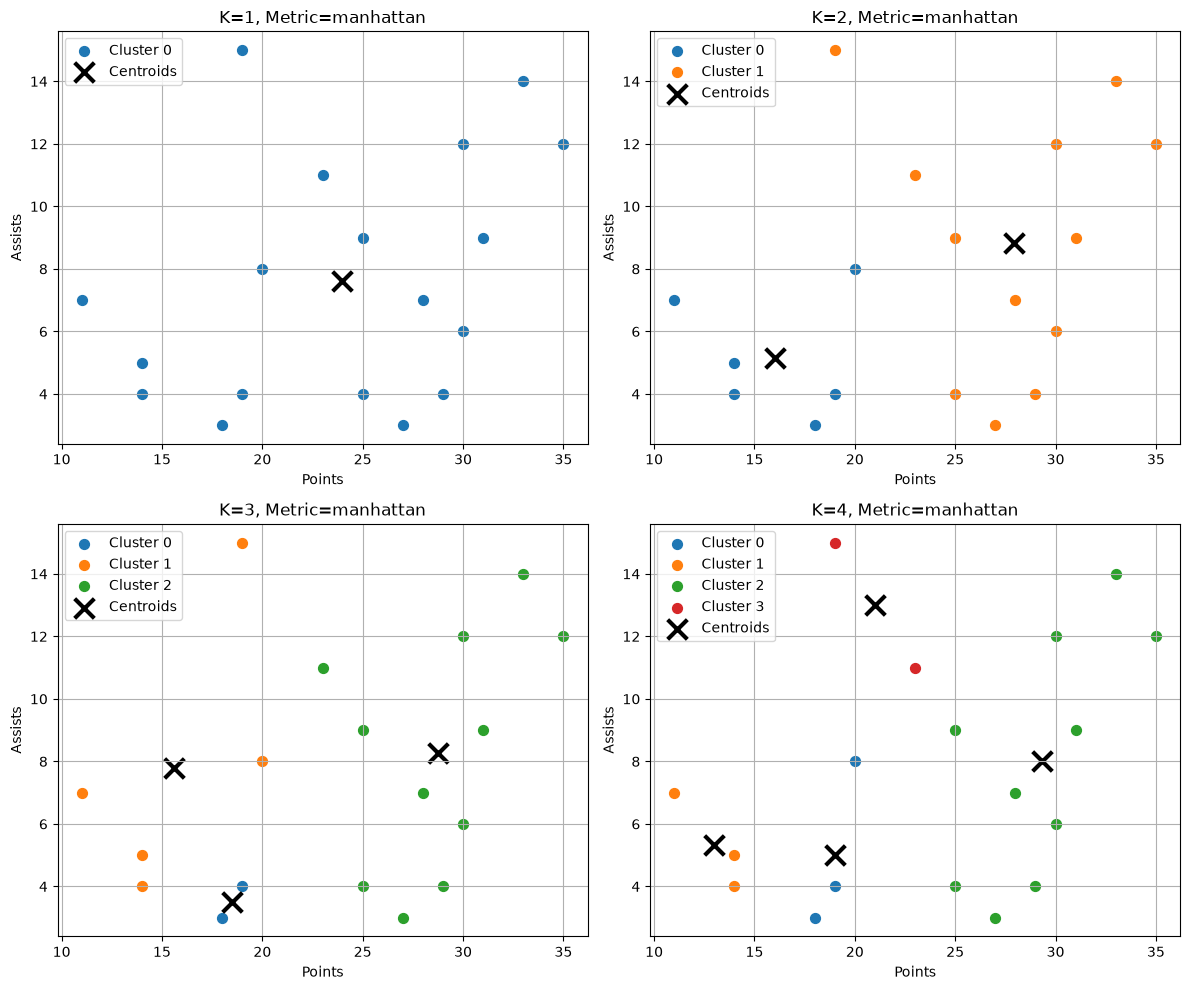

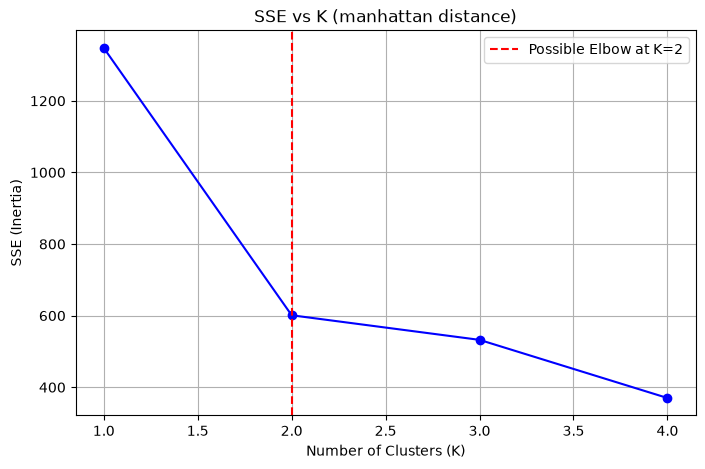

SSE values for K=1 to 4: [np.float64(1347.5000000000002), np.float64(601.0), np.float64(532.3), np.float64(369.93333333333334)]


In [14]:
print("=== Manhattan Distance ===")
sse_manh = analyze_kmeans(X, metric='manhattan')


### f. Minkowski Distance (p=3)

=== Minkowski Distance (p=3) ===


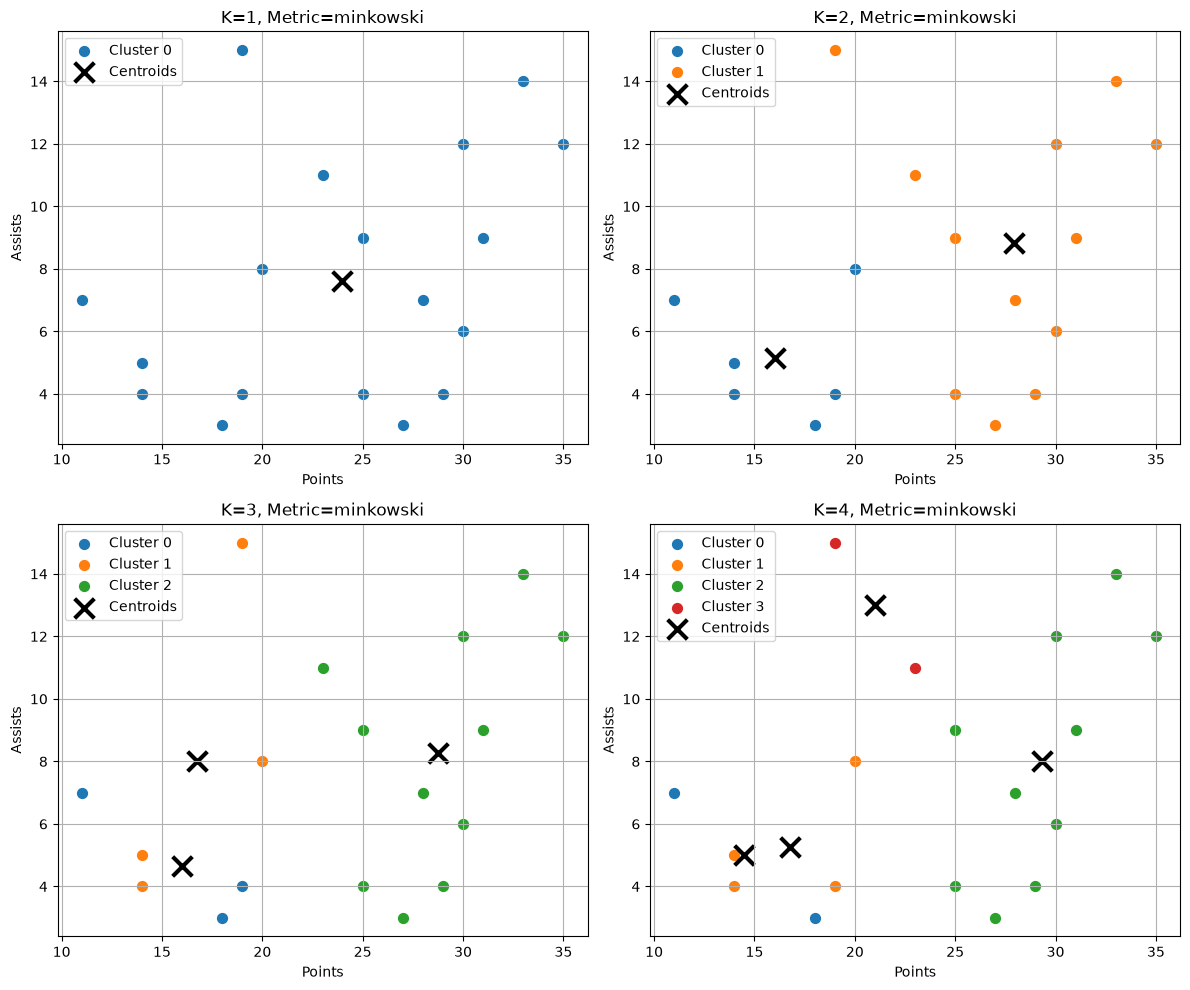

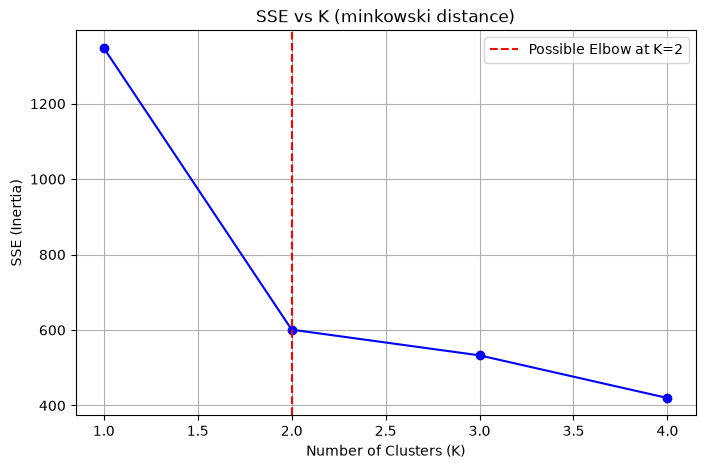

SSE values for K=1 to 4: [np.float64(1347.5000000000002), np.float64(601.0), np.float64(532.8333333333333), np.float64(419.85)]


In [15]:
print("=== Minkowski Distance (p=3) ===")
sse_mink = analyze_kmeans(X, metric='minkowski', p=3)


## Question 2: Agglomerative Hierarchical Clustering (1D Data)
Data points: 18, 22, 25, 27, 42, 43  
Using Single Linkage (min distance).

In [ ]:
points_1d = np.array([18, 22, 25, 27, 42, 43], dtype=float)
print("Data points:", points_1d)

# Initial proximity matrix (absolute differences)
n = len(points_1d)
prox = np.abs(points_1d[:, None] - points_1d[None, :])
np.fill_diagonal(prox, np.inf)          # now works because prox is float
print("\nInitial Proximity Matrix:")
print(pd.DataFrame(prox.round(1), index=points_1d.astype(int), columns=points_1d.astype(int)))

# Manual steps for single linkage
print("\n--- Iteration 1: Merge 42 and 43 (distance=1) ---")
print("Continue merging closest clusters...")
print("Next closest: 25 and 27 (dist=2), then 22 with (25,27), etc.")
print("Final structure shows two main groups: lower values and higher values.")

Data points: [18. 22. 25. 27. 42. 43.]

Initial Proximity Matrix:
      18    22    25    27    42    43
18   inf   4.0   7.0   9.0  24.0  25.0
22   4.0   inf   3.0   5.0  20.0  21.0
25   7.0   3.0   inf   2.0  17.0  18.0
27   9.0   5.0   2.0   inf  15.0  16.0
42  24.0  20.0  17.0  15.0   inf   1.0
43  25.0  21.0  18.0  16.0   1.0   inf

--- Iteration 1: Merge 42 and 43 (distance=1) ---
Continue merging closest clusters...
Next closest: 25 and 27 (dist=2), then 22 with (25,27), etc.
Final structure shows two main groups: lower values and higher values.


Linkage matrix:
[[ 4.  5.  1.  2.]
 [ 2.  3.  2.  2.]
 [ 1.  7.  3.  3.]
 [ 0.  8.  4.  4.]
 [ 6.  9. 15.  6.]]


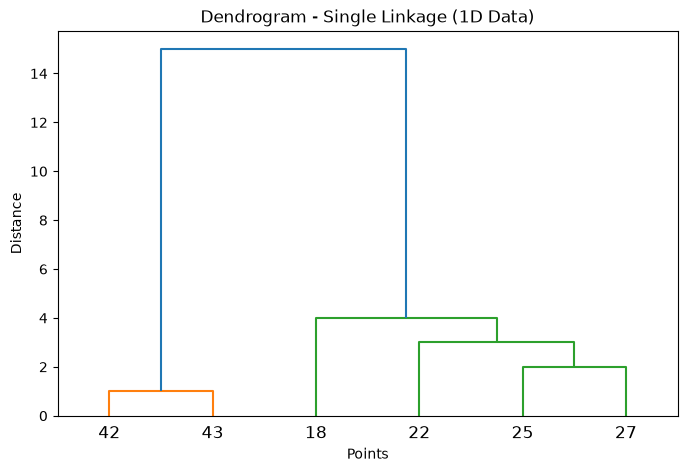

In [20]:
# Using scipy for verification
Z = linkage(points_1d.reshape(-1,1), method='single')
print("Linkage matrix:")
print(Z)

plt.figure(figsize=(8,5))
dendrogram(Z, labels=points_1d)
plt.title('Dendrogram - Single Linkage (1D Data)')
plt.xlabel('Points')
plt.ylabel('Distance')
plt.show()


## Question 3: Hierarchical Clustering on 2D Points
Points:
- p1(1,1), p2(3,2), p3(9,1), p4(3,7), p5(7,2), p6(9,7), p7(4,8), p8(8,3), p9(1,4)

Solve manually for Single, Complete, and Average linkage using Euclidean distance.


In [21]:
pts = np.array([
    [1,1], [3,2], [9,1], [3,7], [7,2], [9,7], [4,8], [8,3], [1,4]
])
labels = [f'p{i+1}' for i in range(9)]
print(pd.DataFrame(pts, index=labels, columns=['x','y']))

# Initial distance matrix
dist_matrix = squareform(pdist(pts, metric='euclidean'))
np.fill_diagonal(dist_matrix, np.inf)
print("\nInitial Euclidean Distance Matrix:")
print(pd.DataFrame(dist_matrix.round(2), index=labels, columns=labels))


    x  y
p1  1  1
p2  3  2
p3  9  1
p4  3  7
p5  7  2
p6  9  7
p7  4  8
p8  8  3
p9  1  4

Initial Euclidean Distance Matrix:
       p1    p2    p3    p4    p5     p6    p7    p8    p9
p1    inf  2.24  8.00  6.32  6.08  10.00  7.62  7.28  3.00
p2   2.24   inf  6.08  5.00  4.00   7.81  6.08  5.10  2.83
p3   8.00  6.08   inf  8.49  2.24   6.00  8.60  2.24  8.54
p4   6.32  5.00  8.49   inf  6.40   6.00  1.41  6.40  3.61
p5   6.08  4.00  2.24  6.40   inf   5.39  6.71  1.41  6.32
p6  10.00  7.81  6.00  6.00  5.39    inf  5.10  4.12  8.54
p7   7.62  6.08  8.60  1.41  6.71   5.10   inf  6.40  5.00
p8   7.28  5.10  2.24  6.40  1.41   4.12  6.40   inf  7.07
p9   3.00  2.83  8.54  3.61  6.32   8.54  5.00  7.07   inf


**Manual Steps Summary:**

**Single Linkage (Min):**  
Start by merging closest pairs. Closest is p1-p9 (~3.0), p2-p5 (~4.1), etc.  
Groups form: left-side points, right-side points.

**Complete Linkage (Max):**  
Merges based on maximum inter-cluster distance, tends to produce more compact clusters.

**Average Linkage:**  
Uses average distances, balances the two.

Detailed step-by-step matrices would be computed iteratively by updating the proximity matrix after each merge. See code verification below.


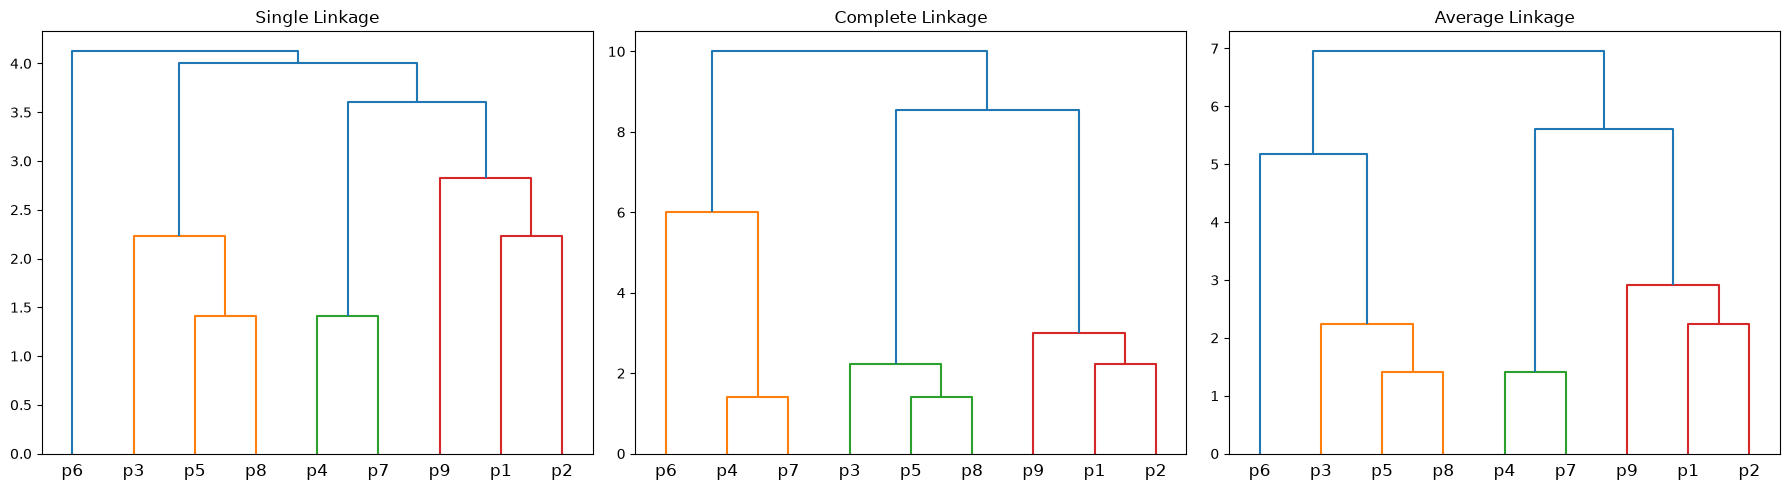

In [22]:
# Verification with scipy
methods = ['single', 'complete', 'average']
fig, axes = plt.subplots(1, 3, figsize=(18,5))

for i, method in enumerate(methods):
    Z = linkage(pts, method=method, metric='euclidean')
    dendrogram(Z, labels=labels, ax=axes[i])
    axes[i].set_title(f'{method.capitalize()} Linkage')

plt.tight_layout()
plt.show()


## Question 4: Hierarchical Clustering on Basketball Data (without scikit-learn)
a. Scatter plot  
b. Proximity matrices for different distances  
c. Dendrograms for single, complete, average


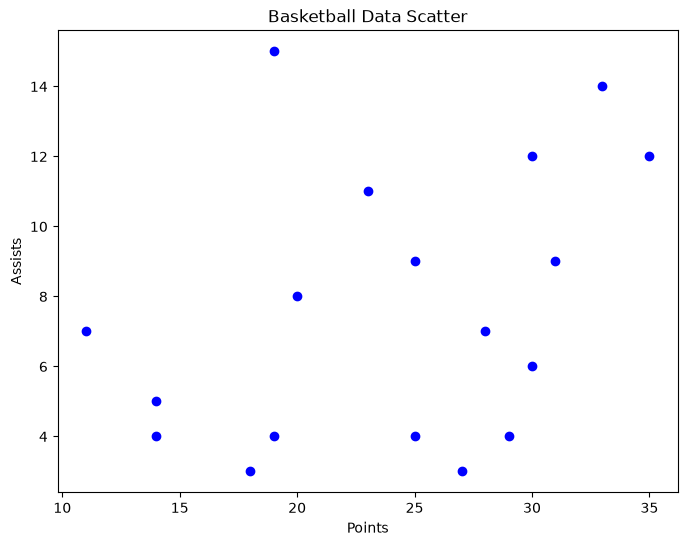

Euclidean Proximity Matrix (sample):
     0    1    2    3    4
0  0.0  1.7  6.7  8.1  8.1
1  1.7  0.0  6.5  7.8  8.5
2  6.7  6.5  0.0  2.2  5.4
3  8.1  7.8  2.2  0.0  7.3
4  8.1  8.5  5.4  7.3  0.0

Manhattan Proximity Matrix (sample):
      0     1     2     3     4
0   0.0   3.0  11.0  12.0  12.0
1   3.0   0.0  10.0  11.0  11.0
2  11.0  10.0   0.0   3.0   9.0
3  12.0  11.0   3.0   0.0  12.0
4  12.0  11.0   9.0  12.0   0.0

Minkowski (p=3) Proximity Matrix (sample):
     0    1    2    3    4
0  0.0  1.4  5.8  7.4  7.4
1  1.4  0.0  5.7  7.0  8.1
2  5.8  5.7  0.0  2.1  4.6
3  7.4  7.0  2.1  0.0  6.5
4  7.4  8.1  4.6  6.5  0.0


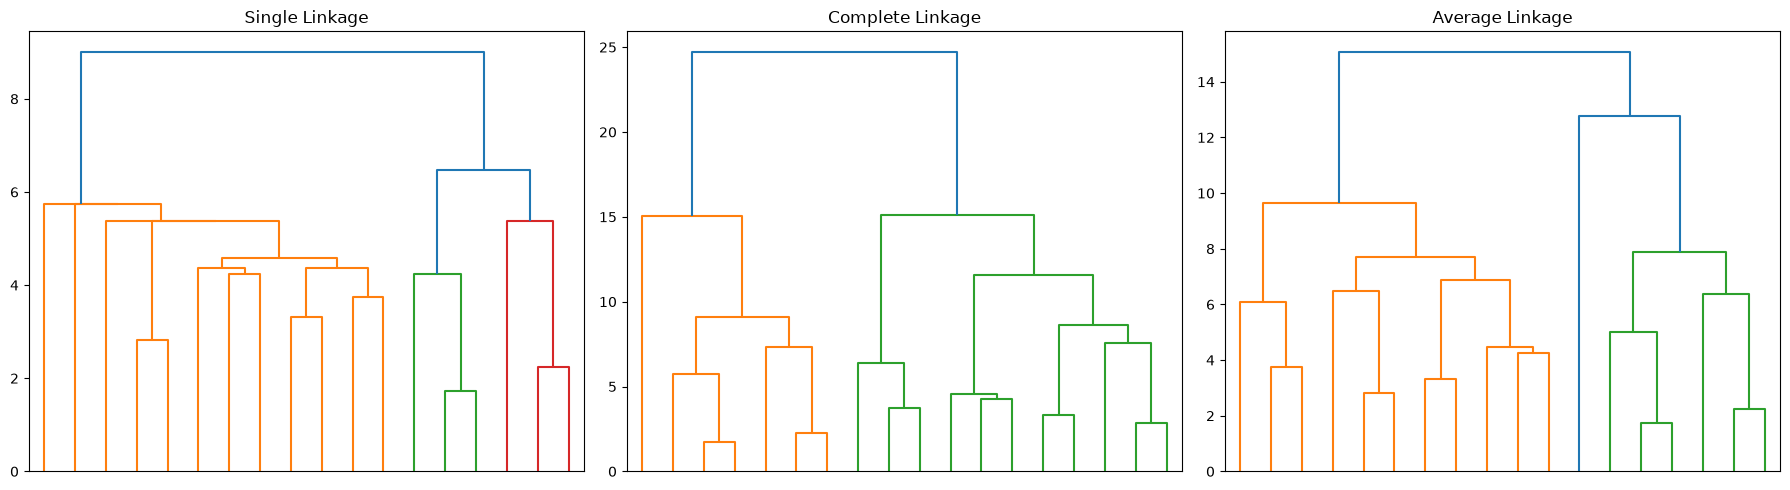

In [23]:
# a. Scatter
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c='blue')
plt.title('Basketball Data Scatter')
plt.xlabel('Points')
plt.ylabel('Assists')
plt.show()

# b. Proximity matrices
print("Euclidean Proximity Matrix (sample):")
eucl_dist = squareform(pdist(X, metric='euclidean'))
print(pd.DataFrame(eucl_dist.round(1)).iloc[:5,:5])

print("\nManhattan Proximity Matrix (sample):")
manh_dist = squareform(pdist(X, metric='cityblock'))
print(pd.DataFrame(manh_dist.round(1)).iloc[:5,:5])

print("\nMinkowski (p=3) Proximity Matrix (sample):")
mink_dist = squareform(pdist(X, metric='minkowski', p=3))
print(pd.DataFrame(mink_dist.round(1)).iloc[:5,:5])

# c. Dendrograms
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for i, method in enumerate(['single', 'complete', 'average']):
    Z = linkage(X, method=method, metric='euclidean')
    dendrogram(Z, ax=axes[i], no_labels=True)
    axes[i].set_title(f'{method.capitalize()} Linkage')
plt.tight_layout()
plt.show()


## Additional Questions (using scikit-learn)

=== sklearn Euclidean ===


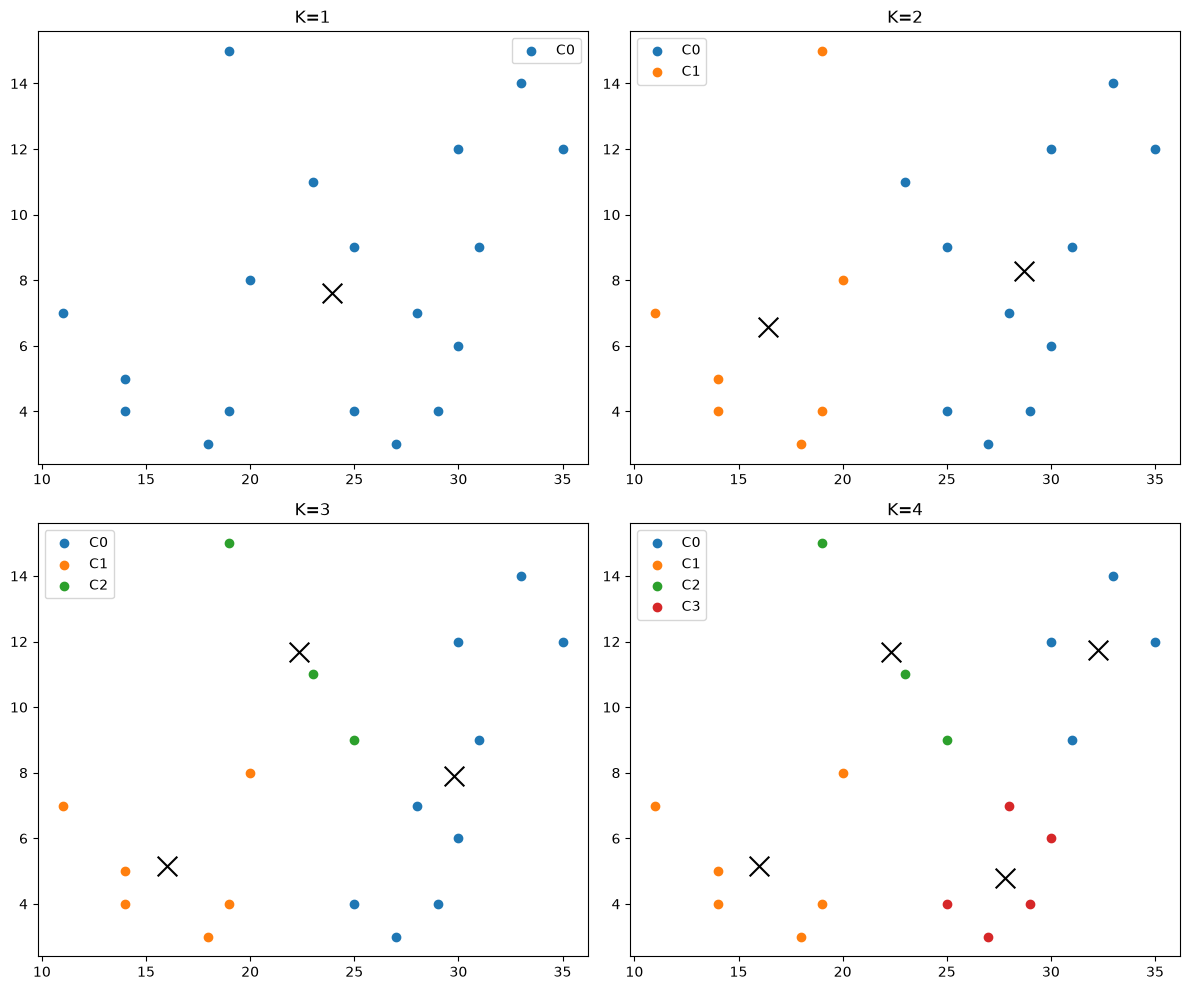

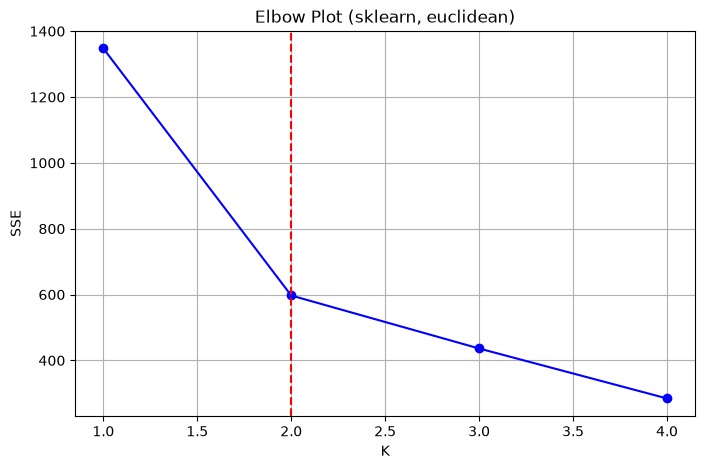

SSE: [1347.5, 597.1428571428572, 436.16666666666663, 284.46666666666664]


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def sklearn_kmeans_analysis(X, metric_note='euclidean'):
    sse = []
    fig, axes = plt.subplots(2, 2, figsize=(12,10))
    axes = axes.ravel()
    
    for idx, k in enumerate(range(1,5)):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X)
        sse.append(km.inertia_)
        
        ax = axes[idx]
        for cluster in range(k):
            mask = labels == cluster
            ax.scatter(X[mask,0], X[mask,1], label=f'C{cluster}')
        ax.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], c='k', marker='x', s=200)
        ax.set_title(f'K={k}')
        ax.legend()
    
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(8,5))
    plt.plot(range(1,5), sse, 'bo-')
    plt.xlabel('K')
    plt.ylabel('SSE')
    plt.title(f'Elbow Plot (sklearn, {metric_note})')
    plt.axvline(x=2, color='r', linestyle='--')
    plt.grid(True)
    plt.show()
    print(f"SSE: {sse}")

print("=== sklearn Euclidean ===")
sklearn_kmeans_analysis(X)


Note: scikit-learn KMeans primarily uses Euclidean. For Manhattan/Minkowski, custom implementation is preferred as shown earlier.